### 1

In [5]:
import numpy as np 
import pandas as pd  
import matplotlib.pyplot as plt  
import seaborn as sns  

In [6]:
df = pd.read_csv("dna_samples.csv")

In [7]:
df

,SampleID,DNA_Sequence
0,S001,ATGCGATCGATCGATC
1,S002,GCGCGCATAT
2,S003,ATGCZNXGATC
3,S004,GGCCGGCC
4,S005,AATTTAAATTT


In [18]:
valid_bases = ['A', 'T', 'G', 'C']
for id, seq in zip(df['SampleID'], df['DNA_Sequence']):
    for base in seq:
        if base in valid_bases:
            continue
        else:
            print(f"its not valid , id :{id}")
            break

its not valid , id :S003


In [9]:
# valid_bases = set('ATGC')

# for id, seq in zip(df['SampleID'], df['DNA_Sequence']):
#   if not set(seq).issubset(valid_bases):
#     print(f'its not valid , id :{id}')

In [10]:
valid_bases = set('ATGC')
summary_rows = []

for sample_id, seq in zip(df['SampleID'], df['DNA_Sequence']):
  # Validate (b)
  if not set(seq).issubset(valid_bases):
    print(f'Warning: {sample_id} contains invalid nucleotides!')
    continue  # Skip invalid sequence from summary

In [11]:
# (c) Calculations
length = len(seq)
count_a = seq.count('A')
count_t = seq.count('T')
count_c = seq.count('C')
count_g = seq.count('G')
gc_pct = ((count_g + count_c) / length) * 100


print(count_g)
print(count_c)
print(count_g + count_c) 
print(gc_pct)

0
0
0
0.0


In [12]:
gc = []
for i, seq in zip(df['SampleID'],df['DNA_Sequence']):
    length = len(seq)
    count_a = seq.count('A')
    count_t = seq.count('T')
    count_c = seq.count('C')
    count_g = seq.count('G')
    gc_cnt = ((count_g + count_c)/length)*100
    gc.append(gc_cnt)
    print(f'for {i} GC Content: {gc_cnt}')
    
print(gc)

for S001 GC Content: 50.0
for S002 GC Content: 60.0
for S003 GC Content: 36.36363636363637
for S004 GC Content: 100.0
for S005 GC Content: 0.0
[50.0, 60.0, 36.36363636363637, 100.0, 0.0]


In [23]:
# Store row for (d)
summary_rows = []

valid_bases = ['A', 'T', 'G', 'C']

for i, seq in zip(df['SampleID'], df['DNA_Sequence']):

    # Validate DNA sequence
    for base in seq:
        if base not in valid_bases:
            print(f'its not valid, id: {i}')
            break
    else:
        # Calculate results
        length = len(seq)

        count_a = seq.count('A')
        count_t = seq.count('T')
        count_c = seq.count('C')
        count_g = seq.count('G')

        gc_cnt = ((count_g + count_c) / length) * 100

        # Store results as a dictionary
        summary_rows.append({
            'SampleID': i,
            'Length': length,
            'A': count_a,
            'T': count_t,
            'C': count_c,
            'G': count_g,
            'GC_Content': gc_cnt
        })
print("~~~~~~~~~~~~~~~~~~~~~~~~~\n", summary_rows)
# Create a new DataFrame
summary_df = pd.DataFrame(summary_rows)

print(summary_df)

its not valid, id: S003
~~~~~~~~~~~~~~~~~~~~~~~~~
 [{'SampleID': 'S001', 'Length': 16, 'A': 4, 'T': 4, 'C': 4, 'G': 4, 'GC_Content': 50.0}, {'SampleID': 'S002', 'Length': 10, 'A': 2, 'T': 2, 'C': 3, 'G': 3, 'GC_Content': 60.0}, {'SampleID': 'S004', 'Length': 8, 'A': 0, 'T': 0, 'C': 4, 'G': 4, 'GC_Content': 100.0}, {'SampleID': 'S005', 'Length': 11, 'A': 5, 'T': 6, 'C': 0, 'G': 0, 'GC_Content': 0.0}]
  SampleID  Length  A  T  C  G  GC_Content
0     S001      16  4  4  4  4        50.0
1     S002      10  2  2  3  3        60.0
2     S004       8  0  0  4  4       100.0
3     S005      11  5  6  0  0         0.0


In [14]:
# (d) Summary DataFrame
summary_df = pd.DataFrame(summary_rows)
print(summary_df)

  SampleID  Length  A  T  C  G  GC_Content
0     S001      16  4  4  4  4        50.0
1     S002      10  2  2  3  3        60.0
2     S004       8  0  0  4  4       100.0
3     S005      11  5  6  0  0         0.0


Text(0.5, 1.0, 'GC Content Percentage by Sample')

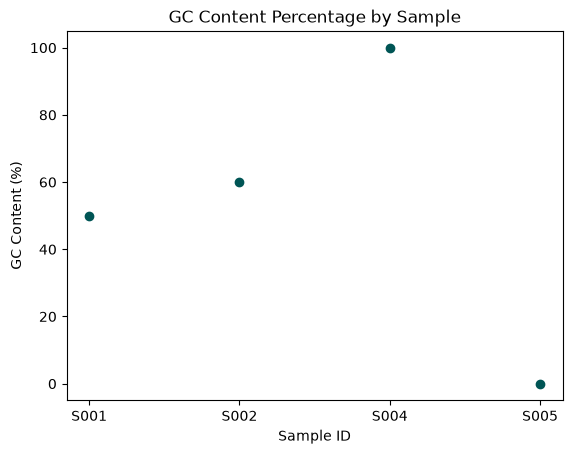

In [28]:
# (e) Plot a bar chart of GC content percentage
plt.scatter(summary_df['SampleID'], summary_df['GC_Content'], color = '#005555')
plt.xlabel('Sample ID')
plt.ylabel('GC Content (%)')
plt.title('GC Content Percentage by Sample')

In [16]:
# (f) Save summary to a CSV file
summary_df.to_csv('dna_summaryyy.csv', index=False)

In [17]:
# names = ['Chathura', 'Kamal', 'Nimal']
# ages = [23, 24, 22]
# course = ['cs', 'it', 'bio']

# for name, age, course in zip(names, ages, course):
#     print(name, age, course)